# Class Cardinality Counter
  ## SUBS
  ### Exact Count
  ### LogLog Counter
  

In [1]:
import random
import pylab as plt
import hashlib

In [ ]:
class CardinalityCounter:
  def add(self,data_item):
    pass
  
  def count(self):
    pass

In [ ]:
class ExactCounter(CardinalityCounter):
  def __init__(self,dataset):
    self.dataset = dataset

  def add(self,data_item):
    self.dataset.append(data_item)

  def count(self):
    dictionary_value_to_count = {}
    for i in self.dataset:
      if i not in dictionary_value_to_count.keys():
        dictionary_value_to_count[i] = 1
    return len(dictionary_value_to_count)

In [ ]:
hashed_value = hash(6)
hashed_value = bin(hashed_value)
hashed_value = hashed_value[2:]
if len(hashed_value) != 64:
  length_string = "0" * (64-len(hashed_value))
  hashed_value = length_string + hashed_value
print(hashed_value, len(hashed_value))

0000000000000000000000000000000000000000000000000000000000000110 64


In [ ]:
class LogLogCounter(CardinalityCounter):
  def __init__(self,dataset,k):
    self.dataset = dataset
    self.ranks_list = [0 for i in range(2**k)]
    self.k = k
    self.m = 2**k

  def add(self,data_item):
    self.dataset.append(data_item)

  def get_binary_hash(self,data_item):
    hashed_value = hash(str(data_item))
    hashed_value = bin(hashed_value)
    #print(hashed_value)
    hashed_value = hashed_value[2::]
    values_bin = ["0","1"]
    
    if hashed_value[0] not in values_bin:
      hashed_value = hashed_value[1::]
    
    if len(hashed_value) != 64:
      length_string = "0" * (64 - len(hashed_value))
      hashed_value = length_string + hashed_value
    return hashed_value

  def count_continuous_zeros(self, binary):
    binary = binary[::-1]
    # Count zeros
    rank = 1
    for i in binary:
      if i == '1':
        break
      else:
        rank += 1
    return rank

  def ranks_set(self):
    for data_item in self.dataset:
      binary_rep = self.get_binary_hash(data_item)
      #print(binary_rep)
      index = binary_rep[0:self.k]
      index = int(index,2)
      # Count continuous zeros from the right
      rank = binary_rep[self.k:]
      rank = self.count_continuous_zeros(rank)

      #print(index,rank)
      if self.ranks_list[index] < rank:
        self.ranks_list[index] = rank

  def count(self,alpha):
    #sum estimators
    sums = sum(self.ranks_list)
    sums = sums / self.m
    return round(alpha * (self.m) * (2**sums))

In [ ]:
bin(hash("1"))

'-0b101001010011101001010000110010110100110101111100100010100001011'

In [ ]:
test_1 = LogLogCounter([],16)
test_1.get_binary_hash('a')

'0011000011111100101100101001110110100100010011100010001100000110'

In [ ]:
test_1.get_binary_hash('14')
#assert len(test_1.get_binary_hash('14')) == 64

'0000010111010100101001100100010001100110101111101010101001101111'

In [ ]:
test_list = [0 for i in range(2**16)]
test_list[3114] = 2

In [ ]:
# Test binary_hash
test_1 = LogLogCounter(['a','b','c','d','e'],16)
test_1.ranks_set()
test_1.count(1)

65543

In [ ]:
test_1 = ExactCounter([])
assert test_1.count() == 0

In [ ]:
test_1.add(1)
test_1.add(2)
test_1.add(3)
assert test_1.count() == 3

In [ ]:
test_1.add('apple')
test_1.add('chuck')
test_1.add(1)
test_1.add(2)

In [ ]:
assert test_1.count() == 5
assert test_1.dataset == [1,2,3,'apple','chuck',1,2]

In [ ]:
assert test_1.count() == 5

# Experiments

In [ ]:
def generate_random_list_string_dataset(length):
  dataset = []
  for i in range(length):
    dataset.append(str(random.randint(0,2**64)))
  return dataset

In [ ]:
# Pass test
assert len(generate_random_list_string_dataset(10)) == 10
for i in generate_random_list_string_dataset(10):
  assert type(i) == str

In [ ]:
def loglog_trial_one(dataset,k,alpha = 1):
  """
  Returns a list of tuple of (actual set cardinality, estimation)
  """

  # Real
  real_estimate = ExactCounter(dataset)
  counted_number = real_estimate.count()

  #Estimate
  estimation = LogLogCounter(dataset,k)
  estimation.ranks_set()
  estimation_final = estimation.count(alpha)
  return (counted_number, estimation_final)

In [ ]:
loglog_trial_one(generate_random_list_string_dataset(10),15,0)

(10, 0)

In [ ]:
def plot_graph_loglog(k,interval,min,max,trials_per_size,alpha):
  x = []
  y = []
  x_line = [i for i in range(min,max,interval)]
  for size in range(min,max,interval):
    real = 0
    estimation = 0
    for trials in range(trials_per_size):
      tup = loglog_trial_one(generate_random_list_string_dataset(size),k,alpha)
      real += tup[0]
      estimation += tup[1]
    real = real / trials_per_size
    estimation = estimation / trials_per_size
    #print(real,estimation)
    x.append(real)
    y.append(estimation)
  plt.plot(x,y,color = 'r',label = "Estimated Cardinality")
  plt.plot(x_line,x_line, color = 'g', label = "Real Cardinality")
  plt.xlabel("Real Dataset Cardinality")
  plt.ylabel("Estimated Dataset Cardinality " + "Alpha:" +str(alpha))
  plt.title("Unique Element Set Cardinality: Real vs. Estimation"+" M =" + str(2**k))
  plt.legend()
  plt.ticklabel_format(style='plain')
  plt.show()
  a,b = np.polyfit((x_line + x_line),(y + x_line),1)
  print("Equation :" + "y =" + str(a)+"x"+ + " " + str(b))

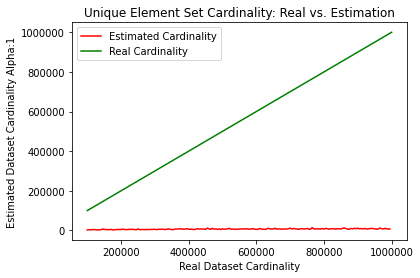

In [ ]:
plot_graph_loglog(4,5000,100000,1000000,1,1)

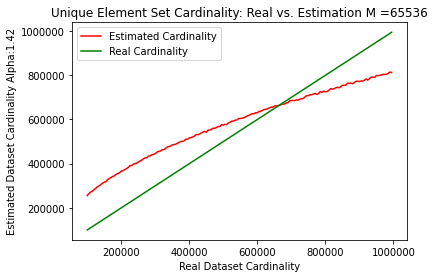

Equation :y =0.7937768115271046x + b


In [ ]:
plot_graph_loglog(16,5000,100000,1000000,1,1.42)

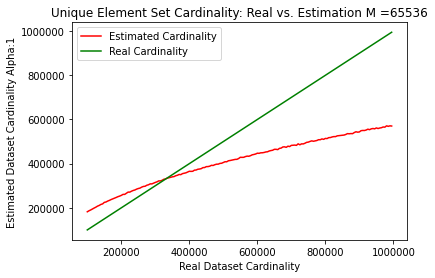

Equation :y =0.7069516919246478x + b


In [ ]:
plot_graph_loglog(16,5000,100000,1000000,1,1)

9.36904761904762


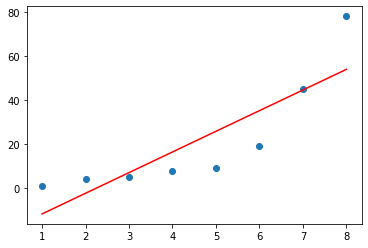

In [ ]:
import numpy as np
x = np.array([1,2,3,4,5,6,7,8])
y = np.array([1,4,5,8,9,19,45,78])
a,b = np.polyfit(x,y,1)

plt.plot(x,(a*x+b),color='r')
plt.scatter(x,y)